Verify the dataset structure

In [3]:
from pathlib import Path

# Detect project root
cwd = Path.cwd()

PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
DATASET_DIR = PROJECT_ROOT / "data/dataset"

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())

# Display dataset structure
def show_tree(directory, max_depth=3, level=0):
    if level > max_depth:
        return

    for item in sorted(directory.iterdir()):
        print("    " * level + ("📁 " if item.is_dir() else "📄 ") + item.name)

        if item.is_dir() and level < max_depth:
            show_tree(item, max_depth, level + 1)

if DATASET_DIR.exists():
    show_tree(DATASET_DIR)
else:
    print("ERROR: Please check the dataset location.")

Project root: c:\Users\wiwir\plate-recognition
Dataset directory: c:\Users\wiwir\plate-recognition\data\dataset
Dataset exists: True
📁 test
    📄 0.jpg
    📄 0.xml
    📄 1.jpg
    📄 1.xml
    📄 10.jpg
    📄 10.xml
    📄 100.jpg
    📄 100.xml
    📄 101.jpg
    📄 101.xml
    📄 102.jpg
    📄 102.xml
    📄 103.jpg
    📄 103.xml
    📄 104.jpg
    📄 104.xml
    📄 105.jpg
    📄 105.xml
    📄 106.jpg
    📄 106.xml
    📄 107.jpg
    📄 107.xml
    📄 108.jpg
    📄 108.xml
    📄 109.jpg
    📄 109.xml
    📄 11.jpg
    📄 11.xml
    📄 110.jpg
    📄 110.xml
    📄 111.jpg
    📄 111.xml
    📄 112.jpg
    📄 112.xml
    📄 113.jpg
    📄 113.xml
    📄 114.jpg
    📄 114.xml
    📄 115.jpg
    📄 115.xml
    📄 116.jpg
    📄 116.xml
    📄 117.jpg
    📄 117.xml
    📄 118.jpg
    📄 118.xml
    📄 119.jpg
    📄 119.xml
    📄 12.jpg
    📄 12.xml
    📄 120.jpg
    📄 120.xml
    📄 121.jpg
    📄 121.xml
    📄 122.jpg
    📄 122.xml
    📄 123.jpg
    📄 123.xml
    📄 124.jpg
    📄 124.xml
    📄 125.jpg
    📄 125.xml
    📄 

Count images and annotations

In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
ANNOTATION_EXTENSION = ".xml"

for split in ["train", "test"]:

    split_dir = DATASET_DIR / split

    if not split_dir.exists():
        print(f"\n{split}: folder not found")
        continue

    images = [
        p for p in split_dir.rglob("*")
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    annotations = list(split_dir.rglob("*.xml"))

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("XML annotations:", len(annotations))
    print("Missing XML:", len(set(p.stem for p in images) -
                              set(p.stem for p in annotations)))



--- TRAIN ---
Images: 567
XML annotations: 567
Missing XML: 0

--- TEST ---
Images: 142
XML annotations: 142
Missing XML: 0


Inspect image dimensions

In [5]:

import cv2
import pandas as pd
from collections import Counter

image_data = []

for split in ["train", "test"]:

    split_dir = DATASET_DIR / split

    for img_path in split_dir.rglob("*"):

        if img_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        image = cv2.imread(str(img_path))

        if image is None:
            image_data.append({
                "split": split,
                "filename": img_path.name,
                "width": None,
                "height": None,
                "status": "Unreadable"
            })
            continue

        height, width = image.shape[:2]

        image_data.append({
            "split": split,
            "filename": img_path.name,
            "width": width,
            "height": height,
            "aspect_ratio": round(width / height, 3),
            "status": "OK"
        })

df_images = pd.DataFrame(image_data)

print(df_images.head())
print("\nImage statistics:")
print(df_images.groupby("split")[["width", "height"]].describe())


   split filename  width  height  aspect_ratio status
0  train  142.jpg   1000     747         1.339     OK
1  train  143.jpg   1000     747         1.339     OK
2  train  144.jpg   1000     747         1.339     OK
3  train  145.jpg   1000     747         1.339     OK
4  train  146.jpg   1000     747         1.339     OK

Image statistics:
       width                                                                \
       count         mean         std    min    25%    50%     75%     max   
split                                                                        
test   142.0   926.901408  537.799896  690.0  690.0  690.0  1000.0  3024.0   
train  567.0  1124.483245  466.987919  360.0  720.0  960.0  1280.0  2000.0   

      height                                                                
       count        mean          std    min    25%    50%     75%     max  
split                                                                       
test   142.0  831.676056  1123.8007

Analyze XML annotations

In [6]:

import xml.etree.ElementTree as ET

annotation_data = []

for split in ["train", "test"]:

    split_dir = DATASET_DIR / split

    for xml_path in split_dir.rglob("*.xml"):

        try:
            root = ET.parse(xml_path).getroot()

            for obj in root.findall("object"):

                class_name = obj.findtext("name")

                box = obj.find("bndbox")

                if box is None:
                    continue

                xmin = int(box.findtext("xmin"))
                ymin = int(box.findtext("ymin"))
                xmax = int(box.findtext("xmax"))
                ymax = int(box.findtext("ymax"))

                annotation_data.append({
                    "split": split,
                    "filename": root.findtext("filename"),
                    "class": class_name,
                    "xmin": xmin,
                    "ymin": ymin,
                    "xmax": xmax,
                    "ymax": ymax,
                    "box_width": xmax - xmin,
                    "box_height": ymax - ymin
                })

        except Exception as e:
            print("XML error:", xml_path.name, e)

df_annotations = pd.DataFrame(annotation_data)

print("Total annotated objects:", len(df_annotations))
print("\nClass distribution:")
print(df_annotations["class"].value_counts())

print("\nBounding box statistics:")
print(df_annotations[["box_width", "box_height"]].describe())


Total annotated objects: 709

Class distribution:
class
LP    709
Name: count, dtype: int64

Bounding box statistics:
        box_width  box_height
count  709.000000  709.000000
mean   199.115656   78.451340
std    107.226623   54.284633
min     38.000000   18.000000
25%    126.000000   47.000000
50%    172.000000   63.000000
75%    243.000000   88.000000
max    918.000000  490.000000


Visualize annotated images

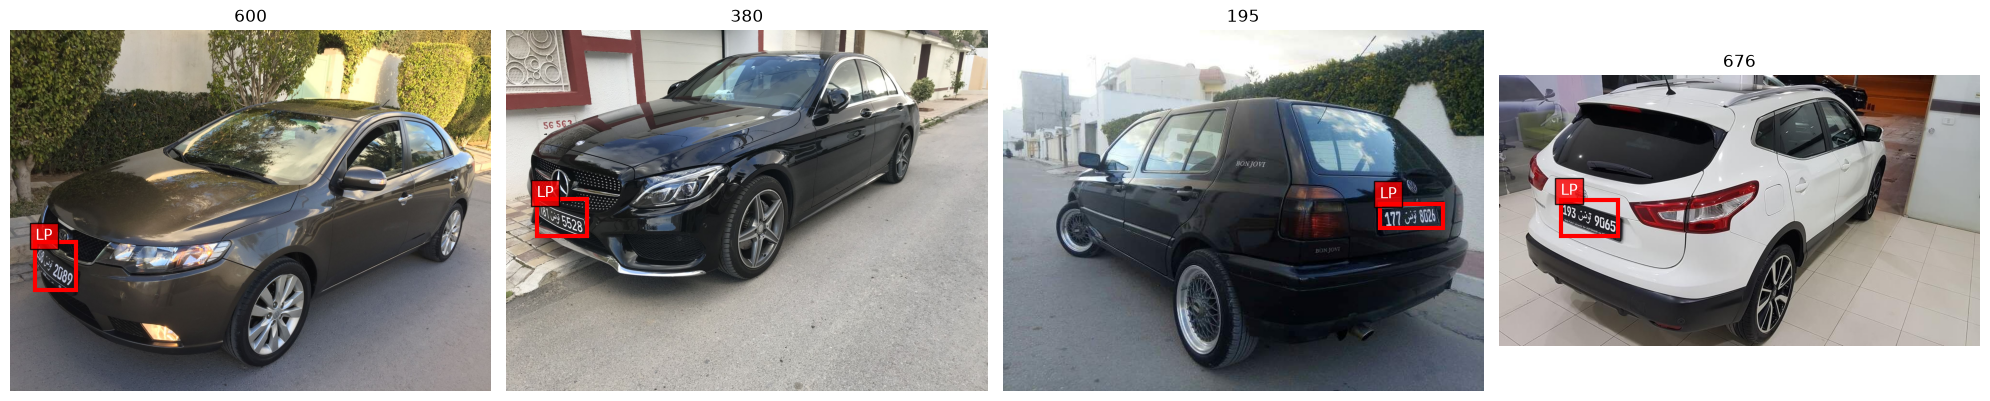

In [10]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import xml.etree.ElementTree as ET
import random

def display_annotated_images(split="train", number=4):

    split_dir = DATASET_DIR / split
    xml_files = list(split_dir.glob("*.xml"))

    selected = random.sample(
        xml_files,
        min(number, len(xml_files))
    )

    fig, axes = plt.subplots(
        1, len(selected),
        figsize=(20, 6)
    )

    if len(selected) == 1:
        axes = [axes]

    for ax, xml_path in zip(axes, selected):

        root = ET.parse(xml_path).getroot()

        # Find corresponding image using XML filename
        image_path = split_dir / (xml_path.stem + ".jpg")

        if not image_path.exists():
            ax.set_title(f"Image not found: {xml_path.stem}")
            ax.axis("off")
            continue

        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        ax.imshow(image)

        for obj in root.findall("object"):

            box = obj.find("bndbox")

            xmin = int(box.findtext("xmin"))
            ymin = int(box.findtext("ymin"))
            xmax = int(box.findtext("xmax"))
            ymax = int(box.findtext("ymax"))

            # Red rectangle around the license plate
            rectangle = patches.Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                linewidth=3,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rectangle)

            ax.text(
                xmin, max(0, ymin - 10),
                "LP",
                color="white",
                fontsize=11,
                bbox=dict(facecolor="red", alpha=0.8)
            )

        ax.set_title(xml_path.stem)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

display_annotated_images("train", 4)


Bounding-box validation

In [11]:

quality_issues = []

for split in ["train", "test"]:

    split_dir = DATASET_DIR / split

    for xml_path in split_dir.glob("*.xml"):

        root = ET.parse(xml_path).getroot()

        image_path = split_dir / (xml_path.stem + ".jpg")
        image = cv2.imread(str(image_path))

        if image is None:
            quality_issues.append({
                "file": xml_path.name,
                "issue": "Image unreadable or missing"
            })
            continue

        height, width = image.shape[:2]

        for obj in root.findall("object"):

            box = obj.find("bndbox")

            xmin = int(box.findtext("xmin"))
            ymin = int(box.findtext("ymin"))
            xmax = int(box.findtext("xmax"))
            ymax = int(box.findtext("ymax"))

            if xmin >= xmax or ymin >= ymax:
                issue = "Invalid bounding box"

            elif xmin < 0 or ymin < 0 or xmax > width or ymax > height:
                issue = "Bounding box outside image"

            else:
                continue

            quality_issues.append({
                "file": xml_path.name,
                "issue": issue
            })

quality_df = pd.DataFrame(quality_issues)

print("Total quality issues:", len(quality_df))
print(quality_df)


Total quality issues: 0
Empty DataFrame
Columns: []
Index: []


Bounding-box distribution

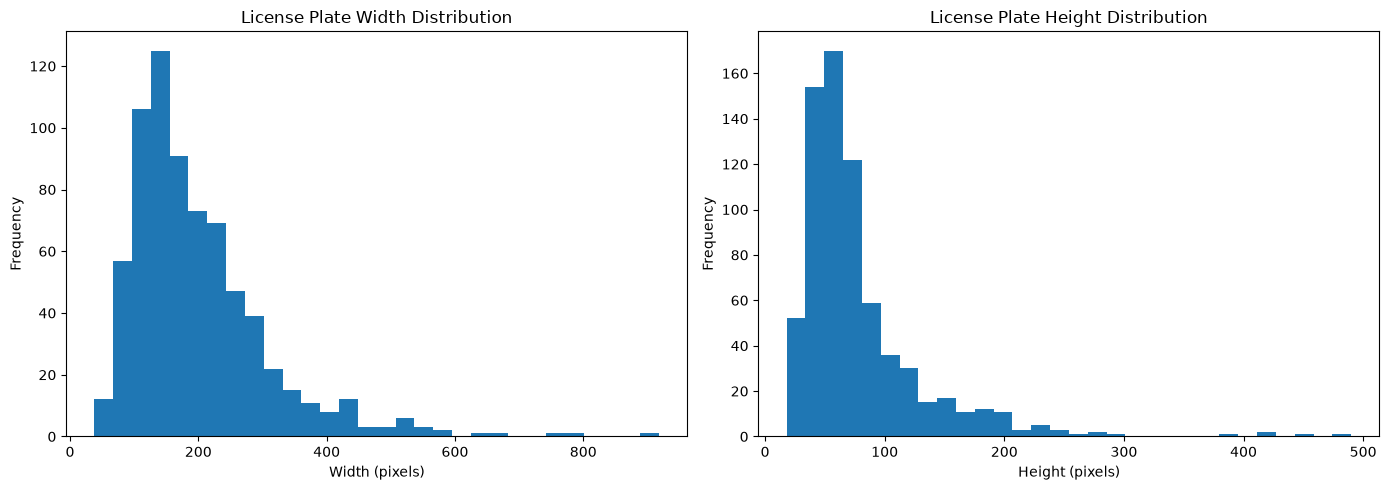

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_annotations["box_width"], bins=30)
axes[0].set_title("License Plate Width Distribution")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Frequency")

axes[1].hist(df_annotations["box_height"], bins=30)
axes[1].set_title("License Plate Height Distribution")
axes[1].set_xlabel("Height (pixels)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


 Compare train and test distributions

In [13]:

print(
    df_annotations.groupby("split")[
        ["box_width", "box_height"]
    ].agg(["mean", "median", "min", "max"])
)


        box_width                 box_height                
             mean median min  max       mean median min  max
split                                                       
test   168.964789  131.0  38  918  60.929577   50.0  18  388
train  206.666667  186.0  54  760  82.839506   67.0  18  490


check the train/test distribution

In [14]:
print("Number of images:")
print(df_images["split"].value_counts())

print("\nAverage image dimensions:")
print(df_images.groupby("split")[["width", "height"]].mean().round(2))

print("\nAverage bounding box dimensions:")
print(
    df_annotations.groupby("split")[["box_width", "box_height"]]
    .mean()
    .round(2)
)

Number of images:
split
train    567
test     142
Name: count, dtype: int64

Average image dimensions:
         width  height
split                 
test    926.90  831.68
train  1124.48  984.69

Average bounding box dimensions:
       box_width  box_height
split                       
test      168.96       60.93
train     206.67       82.84
